### Here we are going to Build a basic chatbot using langgraph and langchain(using GraphAPI) 

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph , START , END
from langgraph.graph.message import add_messages


In [2]:
class State(TypedDict):
    messages : Annotated[list , add_messages]


In [3]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model = "openai/gpt-oss-120b")

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001DC6123B380>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001DC6123BCB0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
def chatbot(state:State):
    return {"messages" : [llm.invoke(state["messages"])]}

In [7]:
graph_builder = StateGraph(State)
graph_builder.add_node("llmchatbot",chatbot)
graph_builder.add_edge(START , "llmchatbot")
graph_builder.add_edge("llmchatbot",END)
graph = graph_builder.compile()


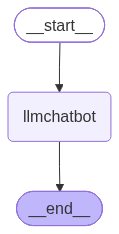

In [8]:
from IPython.display import Image , display

display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
graph.invoke({"messages" : "HI"})

{'messages': [HumanMessage(content='HI', additional_kwargs={}, response_metadata={}, id='e50a5ac6-183d-48e6-a65f-f5d0de9d0aaa'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "HI". Likely a greeting. Should respond politely. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 72, 'total_tokens': 111, 'completion_time': 0.081521779, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.003048164, 'prompt_tokens_details': None, 'queue_time': 0.378456144, 'total_time': 0.084569943}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c868cf1eaa', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20bc2-262a-7449-af66-6366f070f895-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 39, 'total_tokens': 111, 'output_token_details': {'reasoning':

In [10]:
for m in graph.stream({"messages":"hi"}):
    print(m)

{'llmchatbot': {'messages': [AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user just says "hi". We need to respond in a friendly manner. No special constraints. Just greet back.'}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 72, 'total_tokens': 115, 'completion_time': 0.090296172, 'completion_tokens_details': {'reasoning_tokens': 25}, 'prompt_time': 0.002682743, 'prompt_tokens_details': None, 'queue_time': 0.395888154, 'total_time': 0.092978915}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_19b184c447', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20bc2-2e1f-757b-898a-0d9e53f4df67-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 43, 'total_tokens': 115, 'output_token_details': {'reasoning': 25}})]}}


In [11]:
from langchain_tavily import TavilySearch
tool = TavilySearch(max_result = 2)
tool.invoke("what is langgraph")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [12]:
# from langchain_core.tools import tool

# @tool
def mul(a : int , b: int)-> int:
    """Multiply two numbers and return their product."""
    return a * b

In [13]:
tools = [tool , mul]


In [14]:
llm_with_tools = llm.bind_tools(tools)


In [15]:
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.graph import StateGraph , START , END

def tool_calling_llm(state:State):
    return {"messages" : [llm_with_tools.invoke(state["messages"])]}
builder = StateGraph(State)


builder.add_node("tool_calling_llm" ,tool_calling_llm)
builder.add_node("tools" , ToolNode(tools))


builder.add_edge(START , "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", tools_condition
)
builder.add_edge("tools" , "tool_calling_llm")

graph = builder.compile()

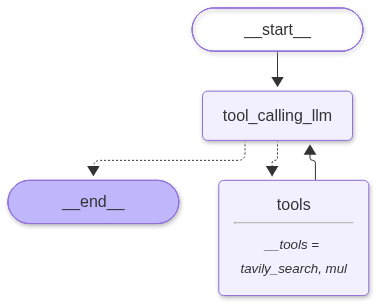

In [16]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
response = graph.invoke({"messages":"what is the recent ai news"})

In [18]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_9e6f86f1-c57d-4d10-a3e8-2e9fb6261709)
 Call ID: fc_9e6f86f1-c57d-4d10-a3e8-2e9fb6261709
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=5XKY4_tbB3Q", "title": "November 2026 AI News: AI Toys, Robots & Google Search", "content": "# November 2026 AI News: AI Toys, Robots & Google Search\n\nAI toys for preschoolers are raising safety questions, and Google’s school search changes are putting AI rules back in the spotlight. Kelly Booz and Sari Beth Rosenberg break down the 

In [19]:
response = graph.invoke({"messages":"what is the recent ai news and multiply 2 and 3"})
for m in response['messages']:
    m.pretty_print()

APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `openai/gpt-oss-120b` in organization `org_01jcq6k7chfqc8xmcrv7d3esdc` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Requested 8019, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

### Now that how we use the LLM with multiple tool query now we have to understandt about Adding memory to Agentic Graph

In [20]:
response = graph.invoke({"messages":"my name is dikshit gupta"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

my name is dikshit gupta
================================== Ai Message ==================================

Nice to meet you, Dikshit Gupta! How can I assist you today?


In [21]:
response = graph.invoke({"messages":"what is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

what is my name
================================== Ai Message ==================================

I’m sorry, but I don’t have any information about your name. If you’d like me to address you a certain way, just let me know!


### Now as we can see that it does not have my name information stored in memory so we have to creat it 

Now for this Langgraph give us a specific checkpointer so that we can keep track of memory 

In [22]:
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.graph import StateGraph , START , END
from langgraph.checkpoint.memory import MemorySaver # THIS IS FOR THE MEMORY 

memory = MemorySaver()

def tool_calling_llm(state:State):
    return {"messages" : [llm_with_tools.invoke(state["messages"])]}
builder = StateGraph(State)


builder.add_node("tool_calling_llm" ,tool_calling_llm)
builder.add_node("tools" , ToolNode(tools))


builder.add_edge(START , "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", tools_condition
)
builder.add_edge("tools" , "tool_calling_llm")

# and we have to pass the checkpointer = memory in this 
graph = builder.compile(checkpointer= memory)

Now we have to creat a thread Id HERE 

In [23]:
# Now here i have to creat a variable config for unique thread_id
config  = {"configurable" : {"thread_id" :"1"}}

# now when we invoke the graph we have to give it this config and that how LLM will understand about memory
response = graph.invoke({"messages":"HI , my name is dikshit"} , config = config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

HI , my name is dikshit
================================== Ai Message ==================================

Hello Dikshit! Nice to meet you. How can I assist you today?


In [24]:
response = graph.invoke({"messages":"what is my name"} , config = config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

HI , my name is dikshit
================================== Ai Message ==================================

Hello Dikshit! Nice to meet you. How can I assist you today?
================================ Human Message =================================

what is my name
================================== Ai Message ==================================

Your name is Dikshit.


### Now let's see how many type streaming(the way LLM can responce) works in langgraph

In [25]:
from langgraph.checkpoint.memory import MemorySaver # THIS IS FOR THE MEMORY 
memory = MemorySaver()

In [26]:
def superbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [27]:
graph_builder = StateGraph(State)

graph_builder.add_node("superbot" , superbot)

graph_builder.add_edge(START , "superbot")
graph_builder.add_edge("superbot" , END)

graph = graph_builder.compile(checkpointer=  memory)

### Now Streaming 
 there are two methods =>  .stream() and astream() (they are basically used for sync and async function in python)

And there are two modes for graph state in streaming:-

value => this stream the full state of the graph after each node is called.

update => this stream update the state of graph after each node is called.


In [ ]:
# now first for updated 
config = {"configurable" : {"thread_id" : "3"}}
for chunks in graph.stream({"messages":"HI , my name is dikshit"} , config,stream_mode="updates"):
    print(chunks)
# here you can see that i only get Ai message

{'superbot': {'messages': [AIMessage(content='Hey there, Dikshit! 👋 Great to meet you. What can I help you with today?', additional_kwargs={'reasoning_content': 'The user says "HI , my name is dikshit". Likely they want a response. Should greet them and ask how can help. Use friendly tone.'}, response_metadata={'token_usage': {'completion_tokens': 63, 'prompt_tokens': 114, 'total_tokens': 177, 'completion_time': 0.129784701, 'completion_tokens_details': {'reasoning_tokens': 33}, 'prompt_time': 0.006747136, 'prompt_tokens_details': None, 'queue_time': 0.329779243, 'total_time': 0.136531837}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8ea50c0161', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20bcb-dfa8-75e9-9ed5-2c6f87cdfa8b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 114, 'output_tokens': 63, 'total_tokens': 177, 'output_token_details': {'reasoning': 33}})]}}


In [ ]:
for chunks in graph.stream({"messages":"HI , my name is dikshit"} , config, stream_mode = "values"):
    print(chunks)

# now you can see that two time human messeg is got and ai message is upendated here basically everything is got displayed

{'messages': [HumanMessage(content='HI , my name is dikshit', additional_kwargs={}, response_metadata={}, id='bfd9e0d7-8b5c-4e3c-8f1c-c72f0eeee3ee'), AIMessage(content='Hello, Dikshit! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "HI , my name is dikshit". Probably they are greeting. We should respond politely, maybe ask how can help. No special instructions. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 65, 'prompt_tokens': 78, 'total_tokens': 143, 'completion_time': 0.135401801, 'completion_tokens_details': {'reasoning_tokens': 37}, 'prompt_time': 0.003484661, 'prompt_tokens_details': None, 'queue_time': 0.323529179, 'total_time': 0.138886462}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_0708ac49a5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20bc4-2a00-70a2-a348-993aae2d3082-0', tool_calls=[], invalid_